# From data to robust surgery schedules
Learning the uncertainty of surgery duration from open data (VitalDB, 6,385 operations) and measuring what it changes in operating-room schedules. Code in `src/`; this notebook shows the results.

In [1]:
import sys; sys.path.insert(0, '../src')
import json, pandas as pd
from IPython.display import Image
pd.set_option('display.precision', 3); pd.set_option('display.width', 160)
from data import load, split, FEATURES

## 1. Data

In [2]:
df = load(); tr, ca, te = split(df)
print(len(df), 'cases;', len(tr), 'train,', len(ca), 'calibration,', len(te), 'test (grouped by patient)')
df['duration'].describe()

6385 cases; 3836 train, 1268 calibration, 1281 test (grouped by patient)


count    6385.000
mean      188.755
std       109.532
min        27.333
25%       103.217
50%       165.283
75%       250.900
max       835.767
Name: duration, dtype: float64

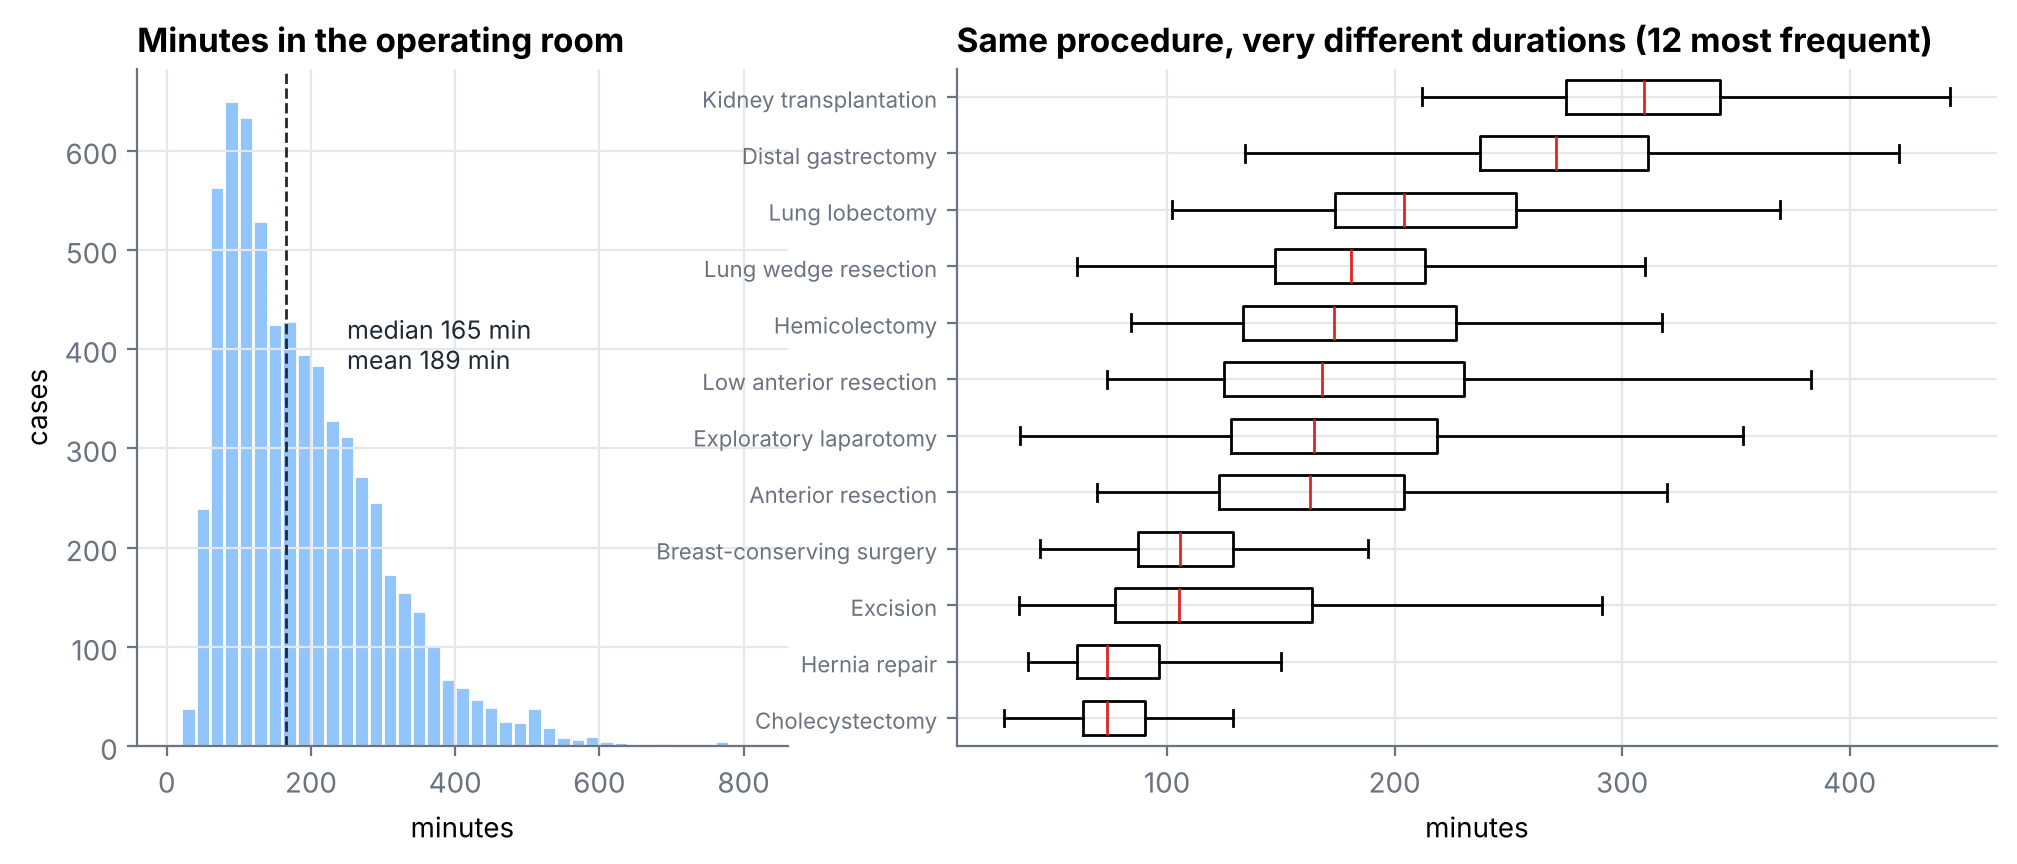

In [3]:
Image('../figures/00_durations.png')

Durations are right-skewed (mean above median) and vary a lot even within one procedure: that variability is what a schedule must absorb.

## 2. Point predictions

In [4]:
pd.read_csv('../results/point_metrics.csv')

,model,MAE_min,RMSE_min,within_30min,R2
0,B0 global median,84.387,111.547,0.192,-0.054
1,B1 procedure history,48.280,71.911,0.488,0.562
2,GBM median,43.898,65.165,0.511,0.640


## 3. Prediction intervals (nominal 80%)

In [5]:
pd.read_csv('../results/interval_metrics.csv')

,method,coverage,mean_width_min,interval_score,worst_department_coverage
0,I1 procedure history,0.781,146.186,236.772,0.467
1,I2 quantile GBM,0.689,123.588,235.272,0.567
2,I3 conformal,0.820,151.359,226.167,0.767
3,I4 CQR,0.816,149.610,230.498,0.600
4,I5 CQR by department,0.815,150.136,230.600,0.600


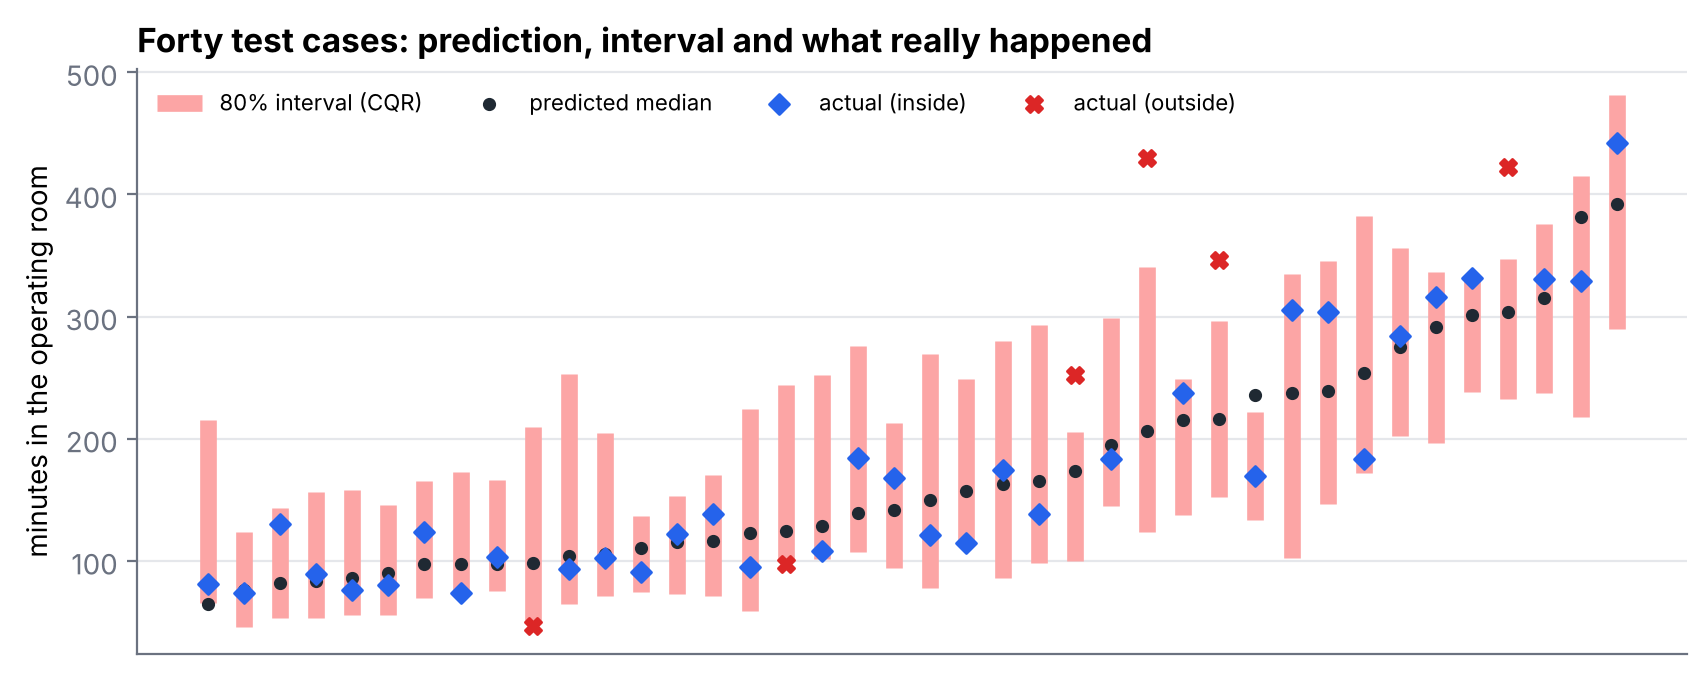

In [6]:
Image('../figures/01_intervals_examples.png')

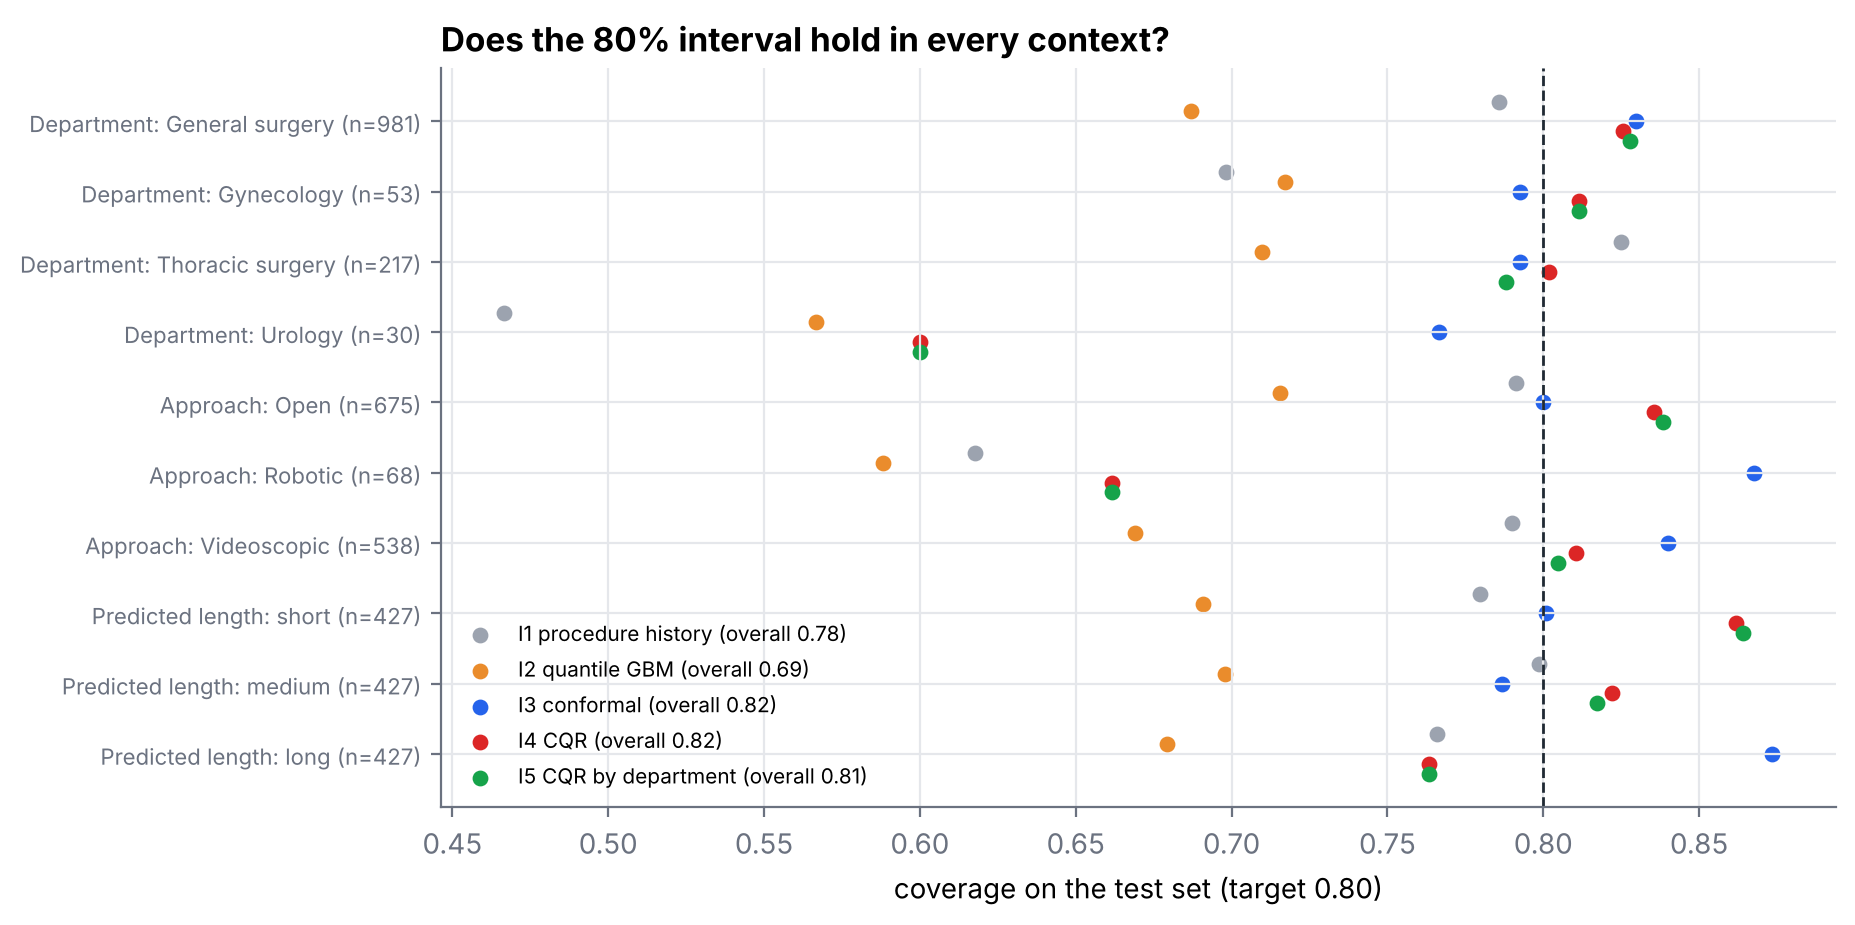

In [7]:
Image('../figures/02_coverage.png')

Over 10 random splits, and paired on the same splits:

In [8]:
pd.read_csv('../results/repeated_splits.csv')

,method,coverage_mean,coverage_sd,width_mean,score_mean,score_sd,worst_dept_cov_mean
0,I1 procedure history,0.765,0.015,146.344,241.721,8.562,0.638
1,I2 quantile GBM,0.677,0.016,122.817,238.715,7.518,0.609
2,I3 conformal,0.805,0.010,150.272,236.847,8.432,0.766
3,I4 CQR,0.801,0.013,148.495,231.463,6.626,0.738
4,I5 CQR by department,0.803,0.013,149.628,231.858,6.424,0.761


In [9]:
pd.read_csv('../results/repeated_splits_paired.csv')

,method,versus,mean_difference,sd,splits_where_better
0,I4 CQR,I1 procedure history,-10.26,4.98,10
1,I4 CQR,I2 quantile GBM,-7.25,1.66,10
2,I4 CQR,I3 conformal,-5.38,4.87,9
3,I5 CQR by department,I4 CQR,0.39,0.48,0


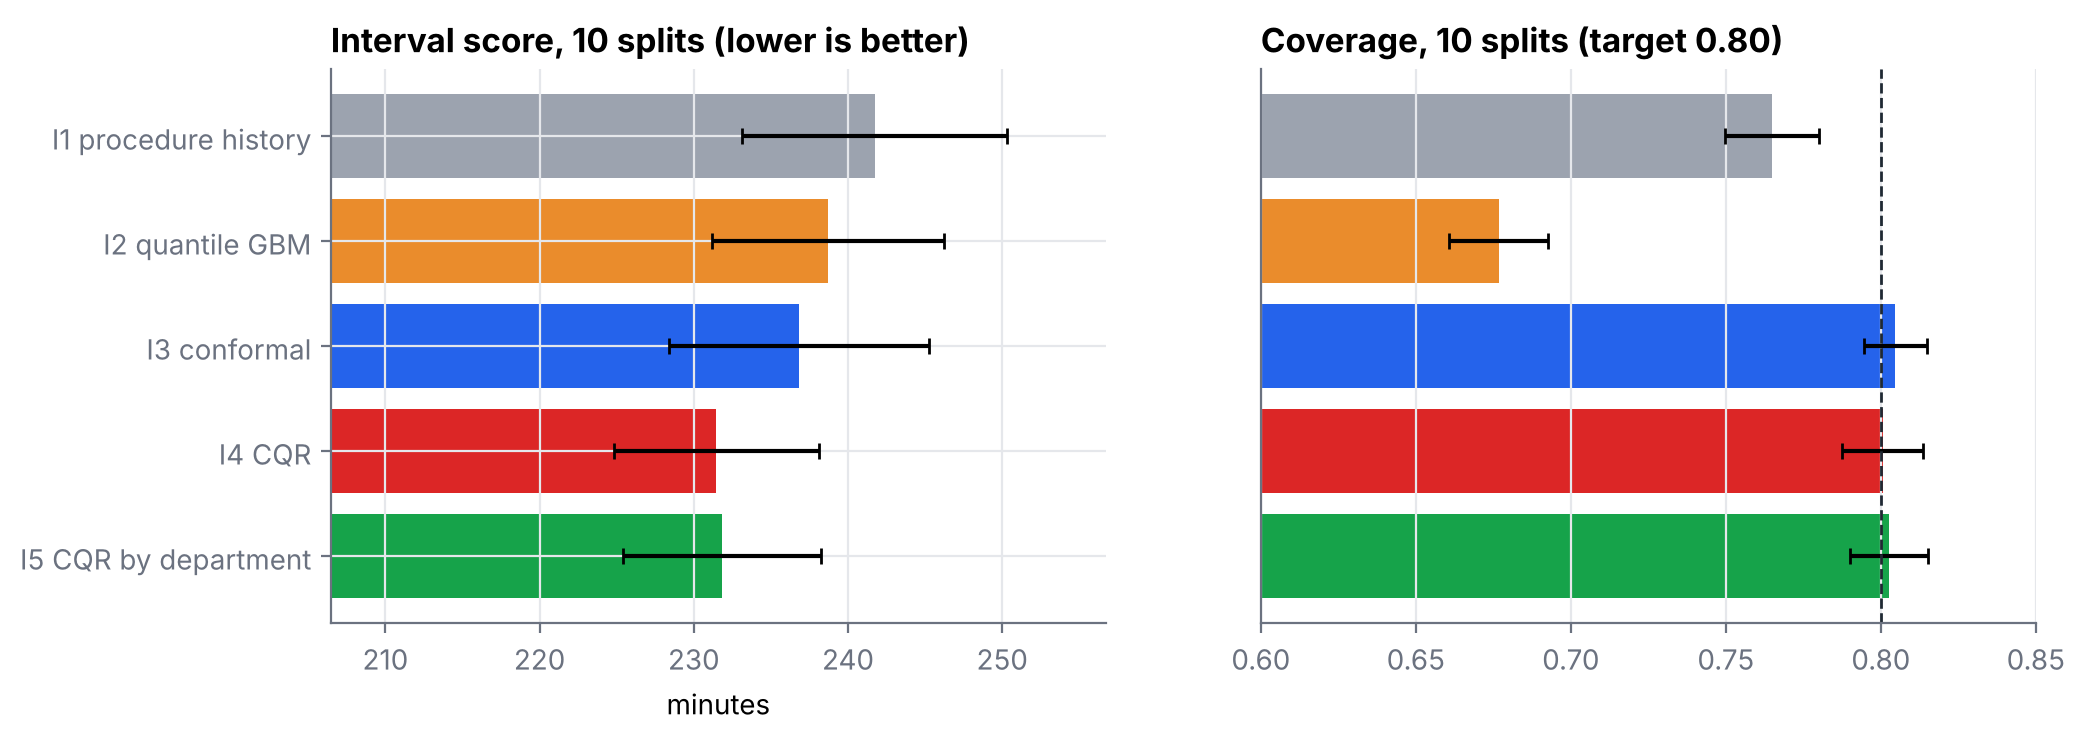

In [10]:
Image('../figures/02b_repeated_splits.png')

## 4. Scheduling under uncertainty
200 simulated days, 4 rooms of 480 minutes, 24 elective cases on the waiting list; exact set-packing model solved with HiGHS, then played with the real durations.

In [11]:
s = pd.read_csv('../results/schedule_summary.csv'); s

,policy,param,overtime_min,rooms_in_overtime,overtime_30,idle_min,utilisation,cases,excess_vs_median,overtime_se
0,ML median,0.00,54.465,0.554,0.426,26.116,0.946,12.560,9.268,2.835
1,fixed buffer,0.05,39.884,0.450,0.335,36.298,0.924,12.005,9.132,2.347
2,fixed buffer,0.10,31.166,0.357,0.260,46.979,0.902,11.595,9.868,2.052
3,fixed buffer,0.15,20.454,0.268,0.186,64.401,0.866,11.210,7.104,1.814
4,fixed buffer,0.20,17.755,0.228,0.154,73.770,0.846,10.865,9.615,1.612
5,fixed buffer,0.30,13.264,0.160,0.124,100.420,0.791,10.175,10.185,1.422
6,historical,0.00,112.816,0.796,0.696,8.866,0.982,12.460,11.808,4.267
7,quantile,0.60,44.950,0.531,0.393,29.975,0.938,10.710,9.717,2.435
8,quantile,0.70,30.960,0.405,0.280,39.244,0.918,10.075,8.624,1.946
9,quantile,0.80,19.249,0.295,0.177,54.150,0.887,9.280,7.018,1.697


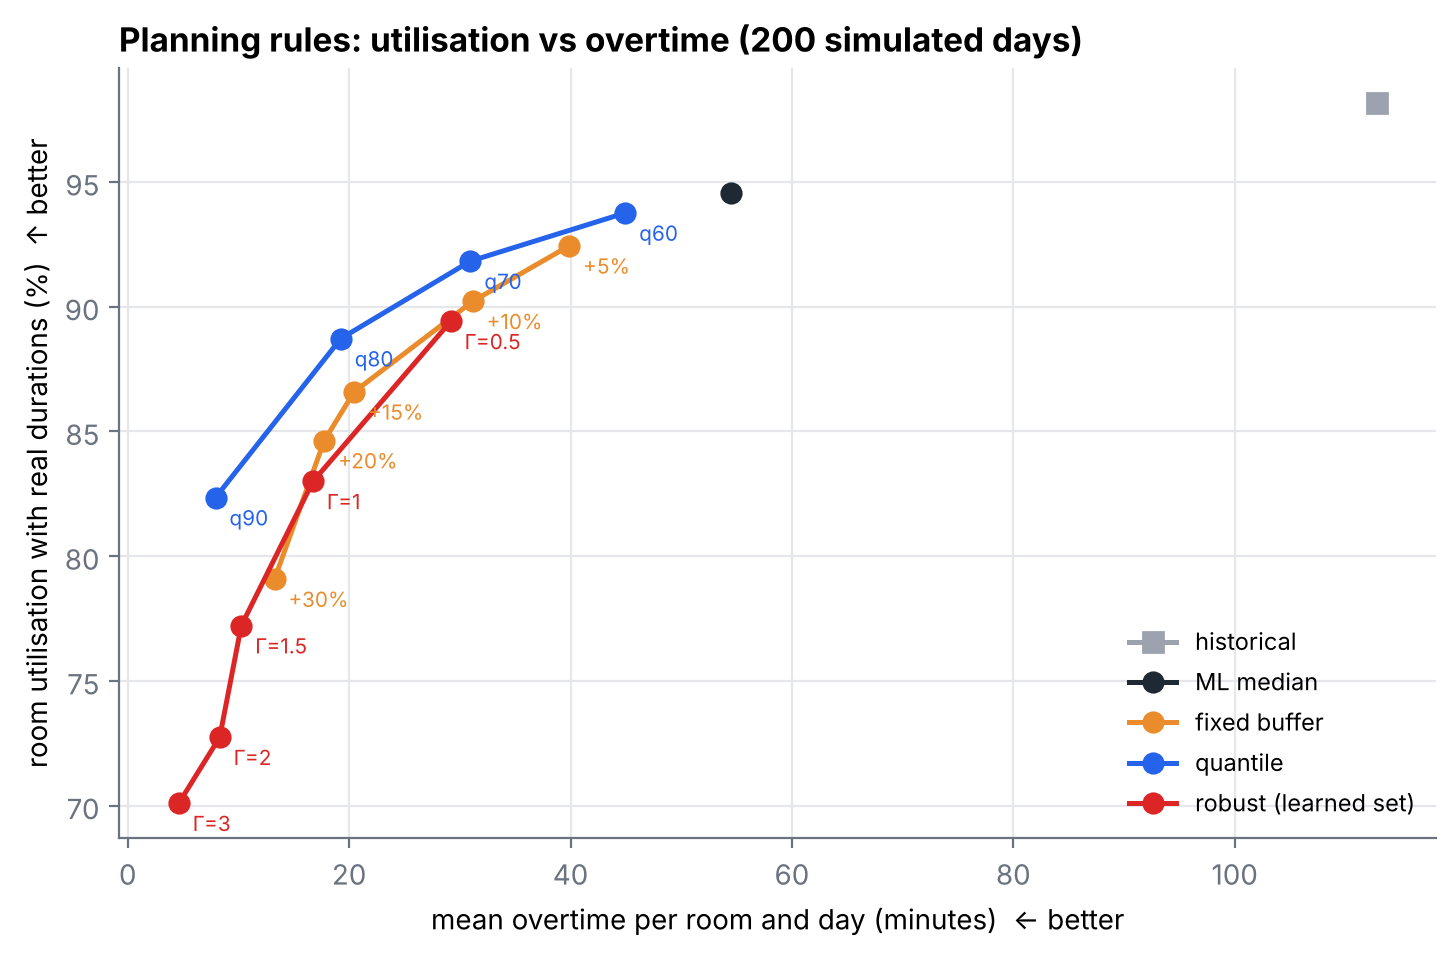

In [12]:
Image('../figures/03_schedule_frontier.png')

## 5. A first step towards FHIR
The first cases exported as HL7 FHIR R4 Patient, Encounter and Procedure resources:

In [13]:
b = json.load(open('../data/fhir_bundle_sample.json')); print(len(b['entry']), 'resources')
print(json.dumps(b['entry'][2]['resource'], indent=1)[:700])

60 resources
{
 "resourceType": "Procedure",
 "id": "procedure-1",
 "status": "completed",
 "subject": {
  "reference": "Patient/patient-5955"
 },
 "encounter": {
  "reference": "Encounter/encounter-1"
 },
 "code": {
  "text": "Low anterior resection"
 },
 "category": {
  "text": "Colorectal"
 },
 "performedPeriod": {
  "start": "2000-01-01T08:00:00+00:00",
  "end": "2000-01-01T11:12:22+00:00"
 },
 "reasonCode": [
  {
   "text": "Rectal cancer"
  }
 ],
 "extension": [
  {
   "url": "urn:surgery-duration-uncertainty:approach",
   "valueString": "Open"
  },
  {
   "url": "urn:surgery-duration-uncertainty:emergency",
   "valueBoolean": false
  }
 ]
}
